<a href="https://colab.research.google.com/github/Themix12/Large-Language-Models-and-Generative-AI-lab-sheet-ID-34970---10965220/blob/main/lab_3_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("Torch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

Torch version: 2.11.0+cpu
Device: cpu


In [ ]:
from datasets import load_dataset

In [ ]:
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

print("Dataset loaded successfully!")
print("Number of stories:", len(dataset))

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Dataset loaded successfully!
Number of stories: 1000


In [ ]:
dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))
print(train_text[:500])

Training stories: 900
Validation stories: 100
Anna and Ben are friends. They like to play together. Today, they have a task. They have to find a beautiful flower for their teacher.

They walk in the park. They see many flowers. Some are red, some are yellow, some are pink. But they want to find the most beautiful flower of all.

They see a big hill. They think maybe there is a beautiful flower on top of the hill. They run to the hill. They jump over rocks and sticks. They climb up the hill. They are tired, but they are happy.

They reach th


In [ ]:
"""Step 3-Convert text into numerical IDs

This experiment uses character-level tokenization: each unique character receives an integer ID.
"""

chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Encoded sample:", encode("Once upon a time")[:10])
print("Decoded sample:", decode(encode("Once upon a time")))

Vocabulary size: 75
Encoded sample: [31, 56, 45, 47, 1, 63, 58, 57, 56, 1]
Decoded sample: Once upon a time


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


In [ ]:
"""Step 4 — Define the tiny Transformer"""

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, 64)
        self.pos_emb = nn.Embedding(64, 64)

        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=2,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        positions = torch.arange(T, device=idx.device)

        x = self.token_emb(idx) + self.pos_emb(positions)

        # Prevent each position from seeing future characters
        mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        x = self.blocks(x, mask=mask)

        return self.lm_head(x)


model = TinyTransformer().to(device)

print(
    "Number of parameters:",
    sum(p.numel() for p in model.parameters())
)


Number of parameters: 80715


In [ ]:
"""Step 5 — Prepare input and target sequences"""

block_size = 64
batch_size = 32

def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)


x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


In [ ]:
"""Step 6 — Train the Transformer"""

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

train_history = []
val_history = []

@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x, y = get_batch(split_name)
        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)


for epoch in range(15):
    model.train()
    total_loss = 0.0

    for step in range(100):
        x, y = get_batch("train")

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    val_loss = evaluate("val", num_batches=10)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}"
    )


Epoch 01 | Train loss: 2.918 | Validation loss: 2.497
Epoch 02 | Train loss: 2.421 | Validation loss: 2.373
Epoch 03 | Train loss: 2.311 | Validation loss: 2.272
Epoch 04 | Train loss: 2.205 | Validation loss: 2.162
Epoch 05 | Train loss: 2.120 | Validation loss: 2.099
Epoch 06 | Train loss: 2.055 | Validation loss: 2.005
Epoch 07 | Train loss: 1.979 | Validation loss: 1.929
Epoch 08 | Train loss: 1.918 | Validation loss: 1.915
Epoch 09 | Train loss: 1.865 | Validation loss: 1.826
Epoch 10 | Train loss: 1.828 | Validation loss: 1.810
Epoch 11 | Train loss: 1.789 | Validation loss: 1.776
Epoch 12 | Train loss: 1.759 | Validation loss: 1.752
Epoch 13 | Train loss: 1.737 | Validation loss: 1.724
Epoch 14 | Train loss: 1.708 | Validation loss: 1.695
Epoch 15 | Train loss: 1.690 | Validation loss: 1.674


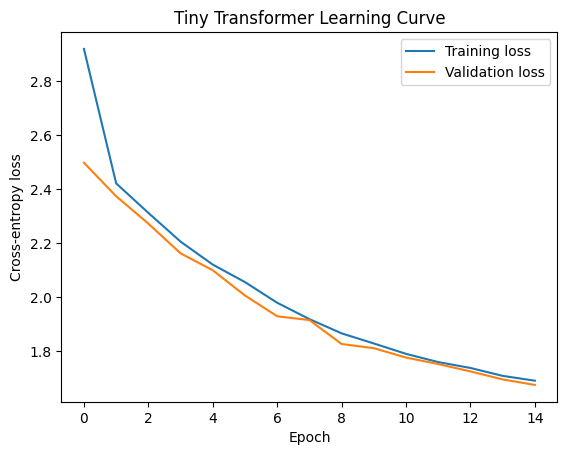

In [ ]:
"""Step 7 — Plot the training and validation losses"""

import matplotlib.pyplot as plt

plt.plot(train_history, label="Training loss")
plt.plot(val_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()
plt.show()

In [ ]:
import math

In [ ]:
"""Step 8 — Calculate validation perplexity


"""

val_loss = evaluate("val", num_batches=20)
val_perplexity = math.exp(min(val_loss, 20))

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}")



Validation loss: 1.6655
Validation perplexity: 5.29


In [ ]:
"""Step 11 — Save the trained model"""

checkpoint = {
    "model_state_dict": model.state_dict(),
    "chars": chars,
    "vocab_size": vocab_size,
    "config": {
        "embedding_dim": 64,
        "num_heads": 2,
        "num_layers": 2,
        "block_size": 64,
        "feedforward_dim": 128
    }
}

torch.save(checkpoint, "tiny_transformer.pt")

print("Model saved successfully!")



Model saved successfully!


In [ ]:
import os
print(os.path.abspath("tiny_transformer.pt"))

/content/tiny_transformer.pt


In [ ]:
"""Step 10 -Built basic chat with the model trained"""

!pip -q install gradio

import gradio as gr

def chat_with_transformer(message, history):
    if not message or not message.strip():
        return "Please enter a message."

    if "stoi" not in globals() or "generate" not in globals():
        return "Error: Please run the cells that define stoi and generate first."

    supported = "".join(ch for ch in message if ch in stoi)

    if not supported:
        return "Please try text using characters in the training dataset."

    try:
        return generate(supported, max_new_chars=100)
    except Exception as e:
        return f"Text generation failed: {type(e).__name__}: {e}"

demo = gr.ChatInterface(
    fn=chat_with_transformer,
    title="My Tiny Transformer Chatbot",
    description="A language model trained from scratch in our LLM class."
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7bff71781311382cb8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
